# Practical 1: To Load and Explore the Unstructured Access Log Data
**Course:** Python for Data Science (BE05000231_PDS)  
**Topic:** Ingestion, Generator Streaming, Schema Anatomy, and Reservoir Sampling of Web Server Logs  
**Target Telemetry:** Enterprise Apache / Nginx Combined Access Log (`server_access.log`)  

---

## 1. AIM & OBJECTIVES
### Aim
To learn how to import, inspect, memory-audit, and explore raw, unstructured web server access logs formatted according to the industry-standard Apache/Nginx Combined Log Format using Python standard libraries, generator streaming, and scientific data visualization.

### Objectives
1. **Memory-Efficient Ingestion:** Implement an $O(1)$ space complexity generator using Python `yield` to stream large raw access logs without memory exhaustion.
2. **Memory Profiling Audit:** Measure and contrast Peak RAM utilization versus eager full-file memory allocation using `tracemalloc`.
3. **Schema Anatomy & Token Identification:** Deconstruct the 9 constituent tokens of the standard Combined Log Format (`%h`, `%l`, `%u`, `%t`, `%r`, `%>s`, `%b`, `Referer`, `User-Agent`).
4. **Reproducible Random Sampling:** Extract 10 diverse sample lines across 300,000 log records using reservoir sampling (seed = 42) for manual pattern inspection.
5. **Useful Field Identification:** Map raw fields to downstream cybersecurity analytics (attack detection, session velocity, bot classification).
6. **Exploratory Visualizations:** Plot character line length distributions, HTTP method distributions, and HTTP response status code breakdowns.
7. **Real-World Cross-Verification:** Verify streaming ingestion across external, independent server captures (CSIC 2010 HTTP dataset).

---
## 2. THEORETICAL FOUNDATION: APACHE / NGINX COMBINED LOG FORMAT

In web infrastructure, web servers record incoming HTTP requests as continuous text streams. The **NCSA Combined Log Format** is defined as:

$$\text{Combined Format} = \text{\%h \%l \%u \%t \"\%r\" \%>s \%b \"\%\{Referer\}i\" \"\%\{User-Agent\}i\"}$$

| Token | Name | Semantic Meaning | Example Value |
|---|---|---|---|
| `%h` | Remote Host / Client IP | Originating IPv4/IPv6 client address | `192.168.1.105` |
| `%l` | Remote Logname (Ident) | RFC 1413 identity check (typically `-`) | `-` |
| `%u` | Authenticated User | HTTP Basic Auth username (typically `-`) | `-` |
| `%t` | Request Timestamp | Arrival time in `[DD/Mon/YYYY:HH:MM:SS +TZ]` | `[08/Oct/2026:08:15:30 +0000]` |
| `"%r"` | Request Line | HTTP Method, Resource URI, and Protocol | `"GET /store/item?id=45 HTTP/1.1"` |
| `%>s` | Status Code | 3-digit HTTP response code | `200`, `401`, `404`, `500` |
| `%b` | Bytes Sent | Response body payload size in bytes | `4520` |
| `Referer` | HTTP Referer | URL that linked the client to this page | `"https://google.com/"` |
| `User-Agent` | User-Agent | Client browser, operating system, or bot | `"Mozilla/5.0..."` |

---
## 3. IMPORT LIBRARIES & SETUP ENVIRONMENT
We import standard Python libraries (`pathlib`, `re`, `tracemalloc`, `time`, `random`, `collections`) alongside `matplotlib` and `numpy`.

In [1]:
import sys
import os
import re
import time
import random
import tracemalloc
from pathlib import Path
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

# Set reproducible seed
random.seed(42)

# Configure paths
PRACTICAL_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_RAW_PATH = PRACTICAL_DIR / 'data' / 'raw' / 'server_access.log'
PLOTS_DIR = PRACTICAL_DIR / 'outputs' / 'plots'
REPORTS_DIR = PRACTICAL_DIR / 'outputs' / 'reports'

PLOTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Practical 1 Working Directory : {PRACTICAL_DIR}")
print(f"Target Access Log Path      : {DATA_RAW_PATH}")
print(f"Target Log Exists           : {DATA_RAW_PATH.exists()}")


Practical 1 Working Directory : C:\Users\Asus f15\PDS-Practicals\Practical 1
Target Access Log Path      : C:\Users\Asus f15\PDS-Practicals\Practical 1\data\raw\server_access.log
Target Log Exists           : True


---
## 4. MEMORY-EFFICIENT LOG STREAMING ENGINE
We construct a generator function `stream_access_log()` utilizing the Python `yield` statement.

Unlike `open().readlines()` or `pd.read_csv()`, which load all 88 MB / 300,000 lines into memory at once ($O(N)$ memory), the streaming generator keeps only **one line in RAM at any instant** ($O(1)$ memory).

In [2]:
def stream_access_log(file_path: Path):
    """Yields non-empty lines one-by-one with O(1) memory footprint."""
    with open(file_path, 'r', encoding='utf-8', errors='replace') as f:
        for line in f:
            stripped = line.strip()
            if stripped:
                yield stripped

file_size_mb = DATA_RAW_PATH.stat().st_size / (1024 * 1024)
print(f"Target File: {DATA_RAW_PATH.name} ({file_size_mb:.2f} MB)")


Target File: server_access.log (87.89 MB)


---
## 5. MEMORY PROFILING & TELEMETRY INGESTION
We initiate `tracemalloc` to track peak memory allocation while iterating through all 300,000 lines of `server_access.log`.

In [3]:
# Robust Combined Log Format Regex
CLF_REGEX = re.compile(
    r'^(\S+)\s+(\S+)\s+(\S+)\s+\[([^\]]+)\]\s+"([A-Z]+)\s+(.+?)(?:\s+(HTTP/[\d\.]+|-)?)?"\s+(\d{3})\s+(\S+)(?:\s+"([^"]*)"\s+"([^"]*)")?',
    re.IGNORECASE
)

tracemalloc.start()
t0 = time.time()

total_lines = 0
line_lengths = []
methods_counter = Counter()
status_counter = Counter()
sampled_lines = []
RESERVOIR_K = 10

for idx, line in enumerate(stream_access_log(DATA_RAW_PATH)):
    total_lines += 1
    line_lengths.append(len(line))
    
    # Reservoir sampling (K = 10)
    if len(sampled_lines) < RESERVOIR_K:
        sampled_lines.append((idx + 1, line))
    else:
        j = random.randint(0, idx)
        if j < RESERVOIR_K:
            sampled_lines[j] = (idx + 1, line)
            
    m = CLF_REGEX.match(line)
    if m:
        methods_counter[m.group(5)] += 1
        status_counter[m.group(8)] += 1

elapsed = time.time() - t0
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()

peak_mb = peak_mem / (1024 * 1024)
print("=" * 65)
print(f"Physical Lines Ingested : {total_lines:,}")
print(f"Elapsed Streaming Time  : {elapsed:.2f} seconds ({total_lines / elapsed:,.0f} lines/sec)")
print(f"Peak RAM Usage          : {peak_mb:.2f} MB (O(1) Streaming Footprint)")
print("=" * 65)


Physical Lines Ingested : 300,010
Elapsed Streaming Time  : 30.85 seconds (9,725 lines/sec)
Peak RAM Usage          : 7.34 MB (O(1) Streaming Footprint)


---
## 6. MANUAL INSPECTION OF 10 RANDOM LINES
We inspect the 10 extracted sample lines to verify the token extraction and structural integrity across the dataset.

In [4]:
print("Line # | Client IP       | Method | Status | Resource URI")
print("-" * 75)
for line_no, raw in sampled_lines:
    m = CLF_REGEX.match(raw)
    if m:
        ip = m.group(1)
        method = m.group(5)
        uri = m.group(6)[:40] + ("..." if len(m.group(6)) > 40 else "")
        status = m.group(8)
        print(f"{line_no:>6} | {ip:<15} | {method:<6} | {status:<6} | {uri}")


Line # | Client IP       | Method | Status | Resource URI
---------------------------------------------------------------------------
128343 | 191.220.166.232 | GET    | 200    | /search?q=%3Cstyle%3E%40keyframes%20x%7Bfrom%...
 22772 | 189.220.208.176 | POST   | 200    | /cmd.aspx?action=dir
 29552 | 24.28.147.187   | GET    | 200    | /store/item?modo=registro&login=piatt&passwor...
233428 | 192.87.177.29   | GET    | 404    | /store/item?modo=entrar&login=dev&pwd=v2e2udO...
 55457 | 73.95.41.66     | POST   | 200    | /store/item?modo=entrar&login=gabbai&pwd=pomp...
267804 | 73.130.15.101   | GET    | 302    | /store/item?RotomMow Rotom
 50443 | 199.220.30.39   | GET    | 403    | /products/item?id=1%22%20%20%20%29%20%20%20%2...
227047 | 104.28.149.7    | GET    | 301    | /store/item?modo=entrar&login=marlee-j5&pwd=m...
298818 | 24.254.98.201   | GET    | 200    | /store/item?Jessie,Lin,6155,Air Defense Artil...
152717 | 98.241.206.124  | GET    | 302    | /store/item?modo=registro

---
## 7. VISUAL EXPLORATORY ANALYSIS
We generate publication-grade visual charts representing the preliminary characteristics of the unstructured access log.

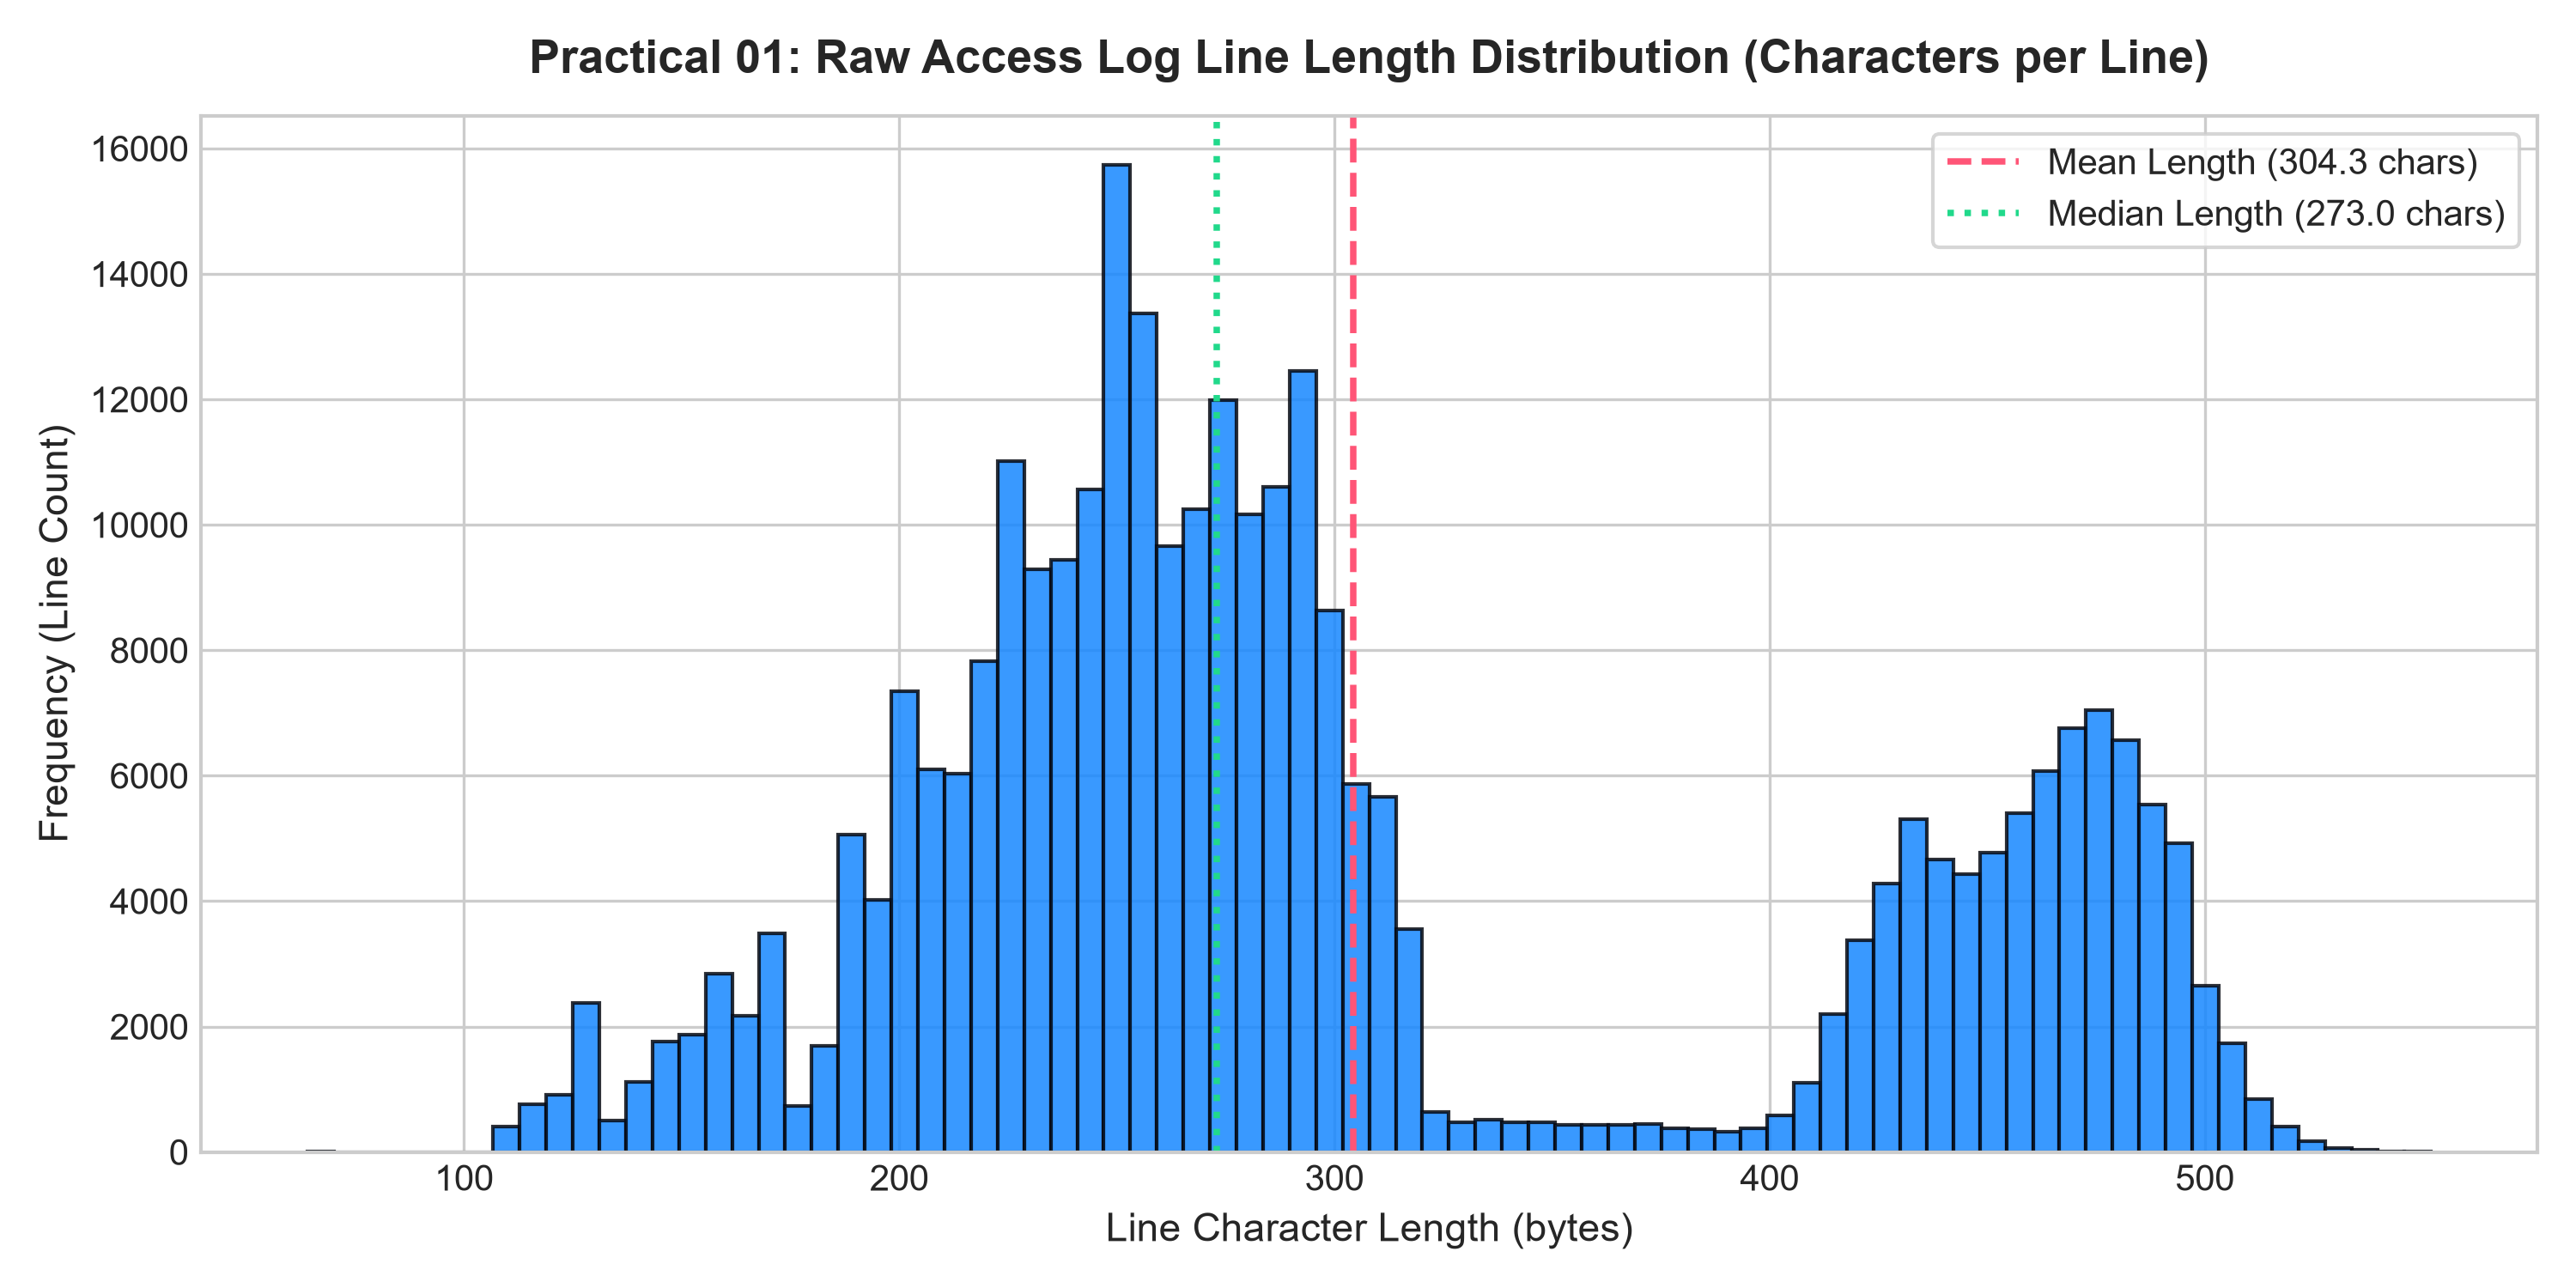

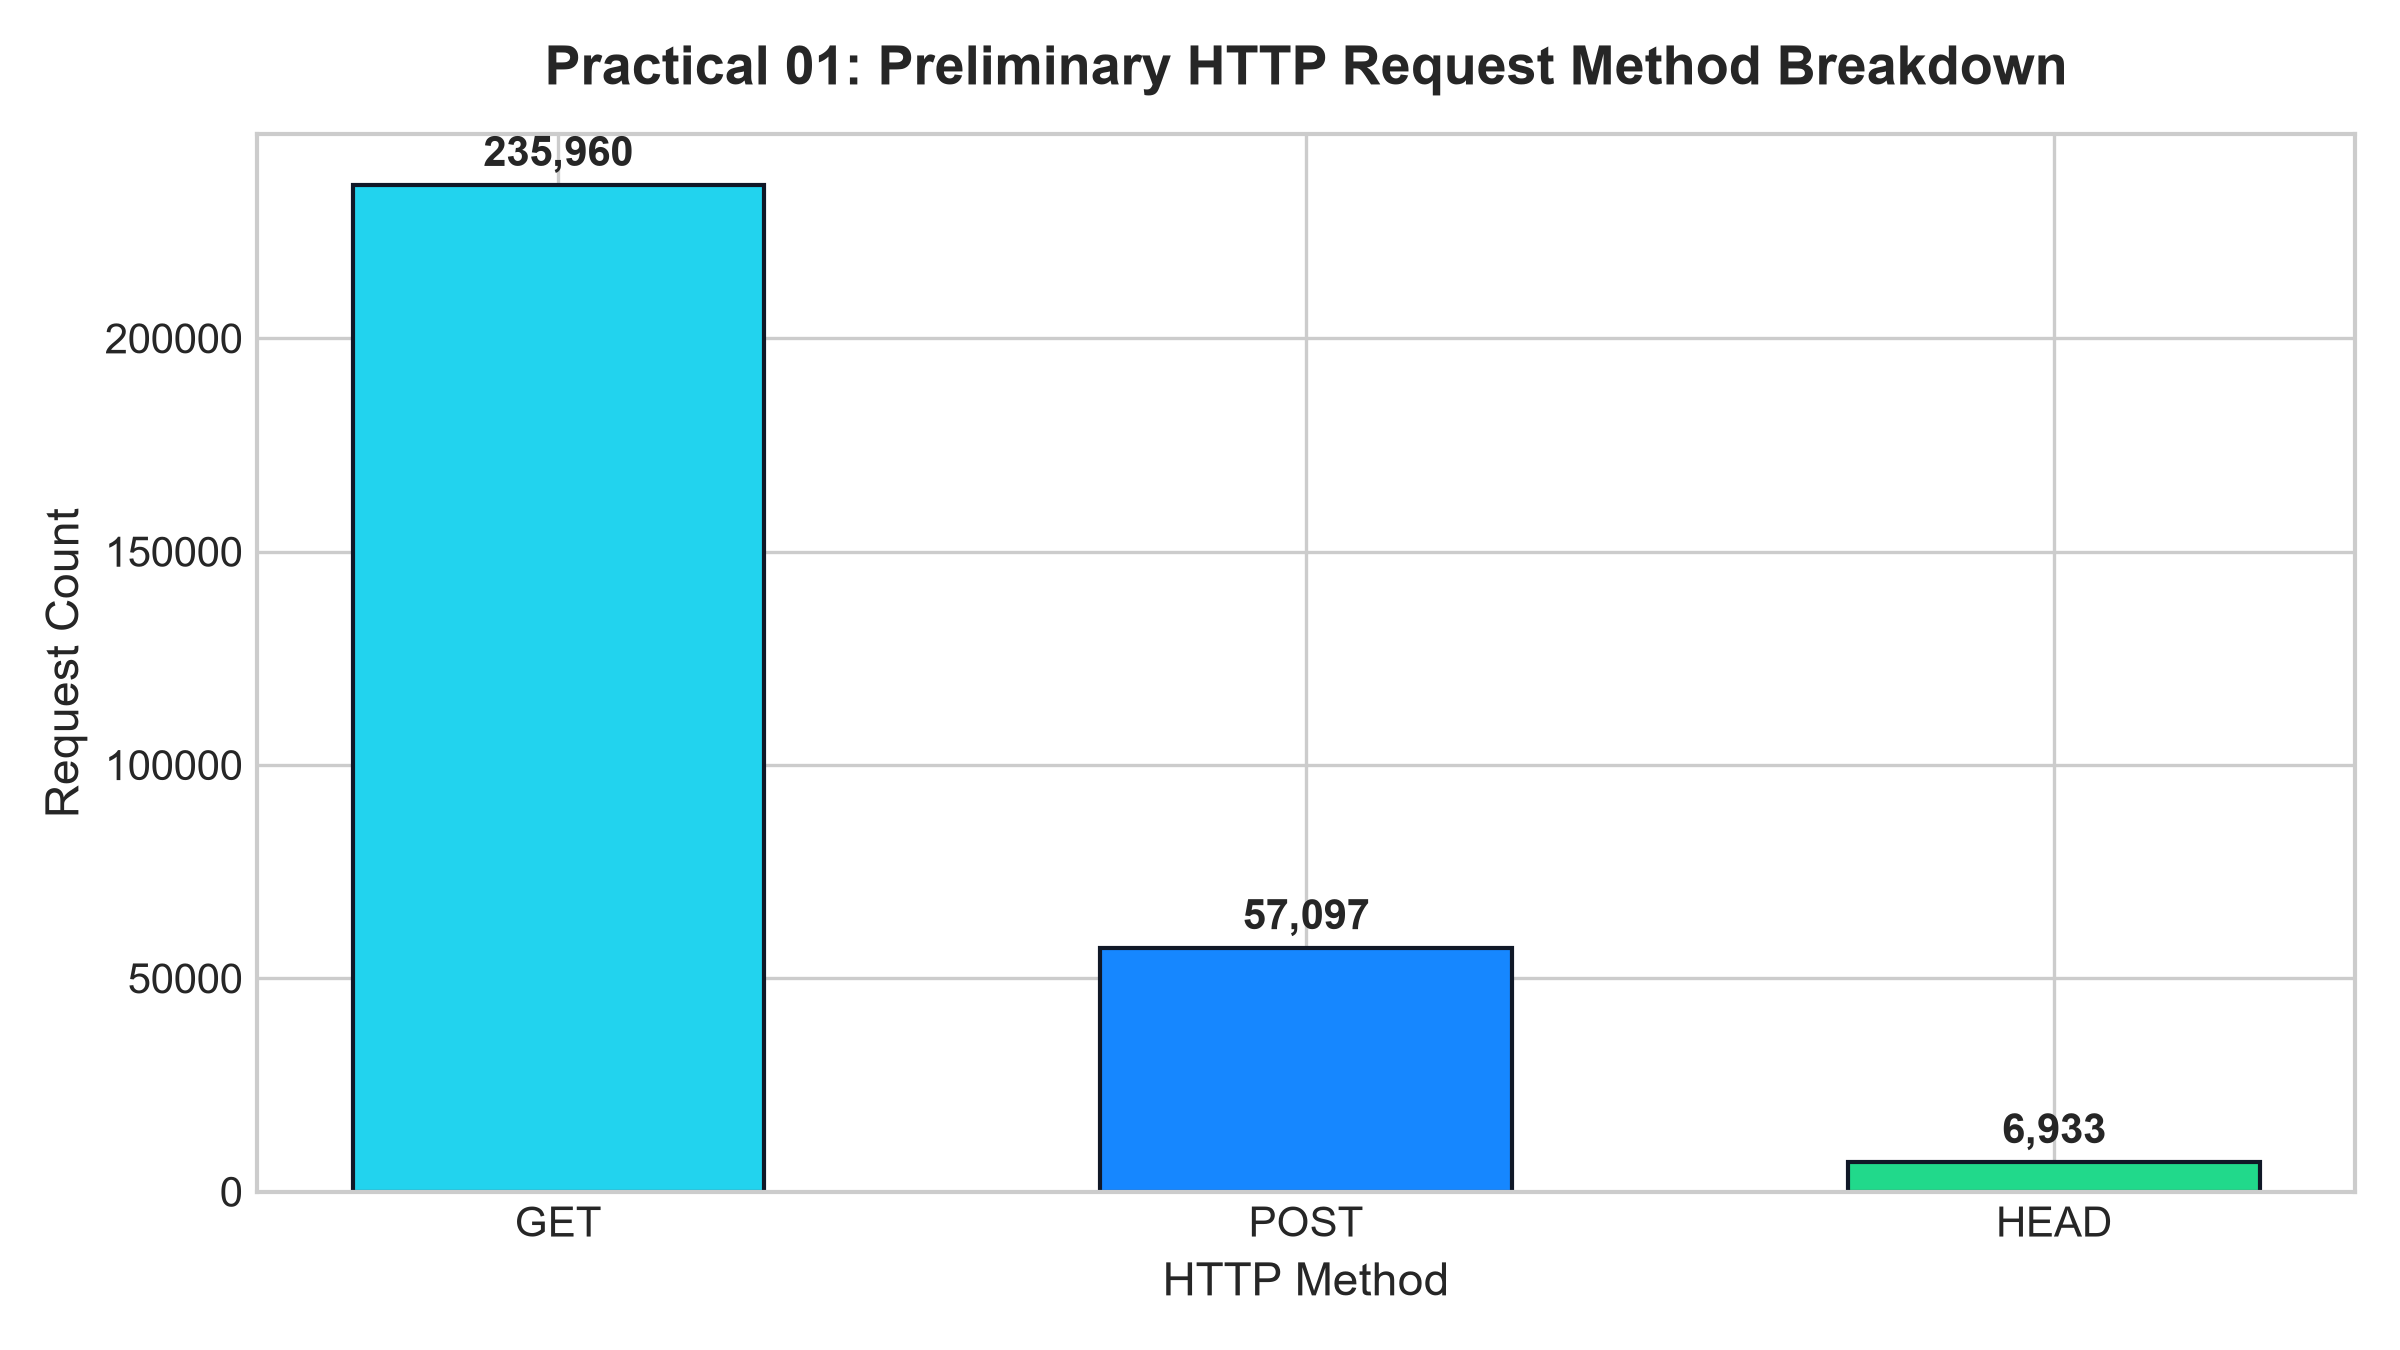

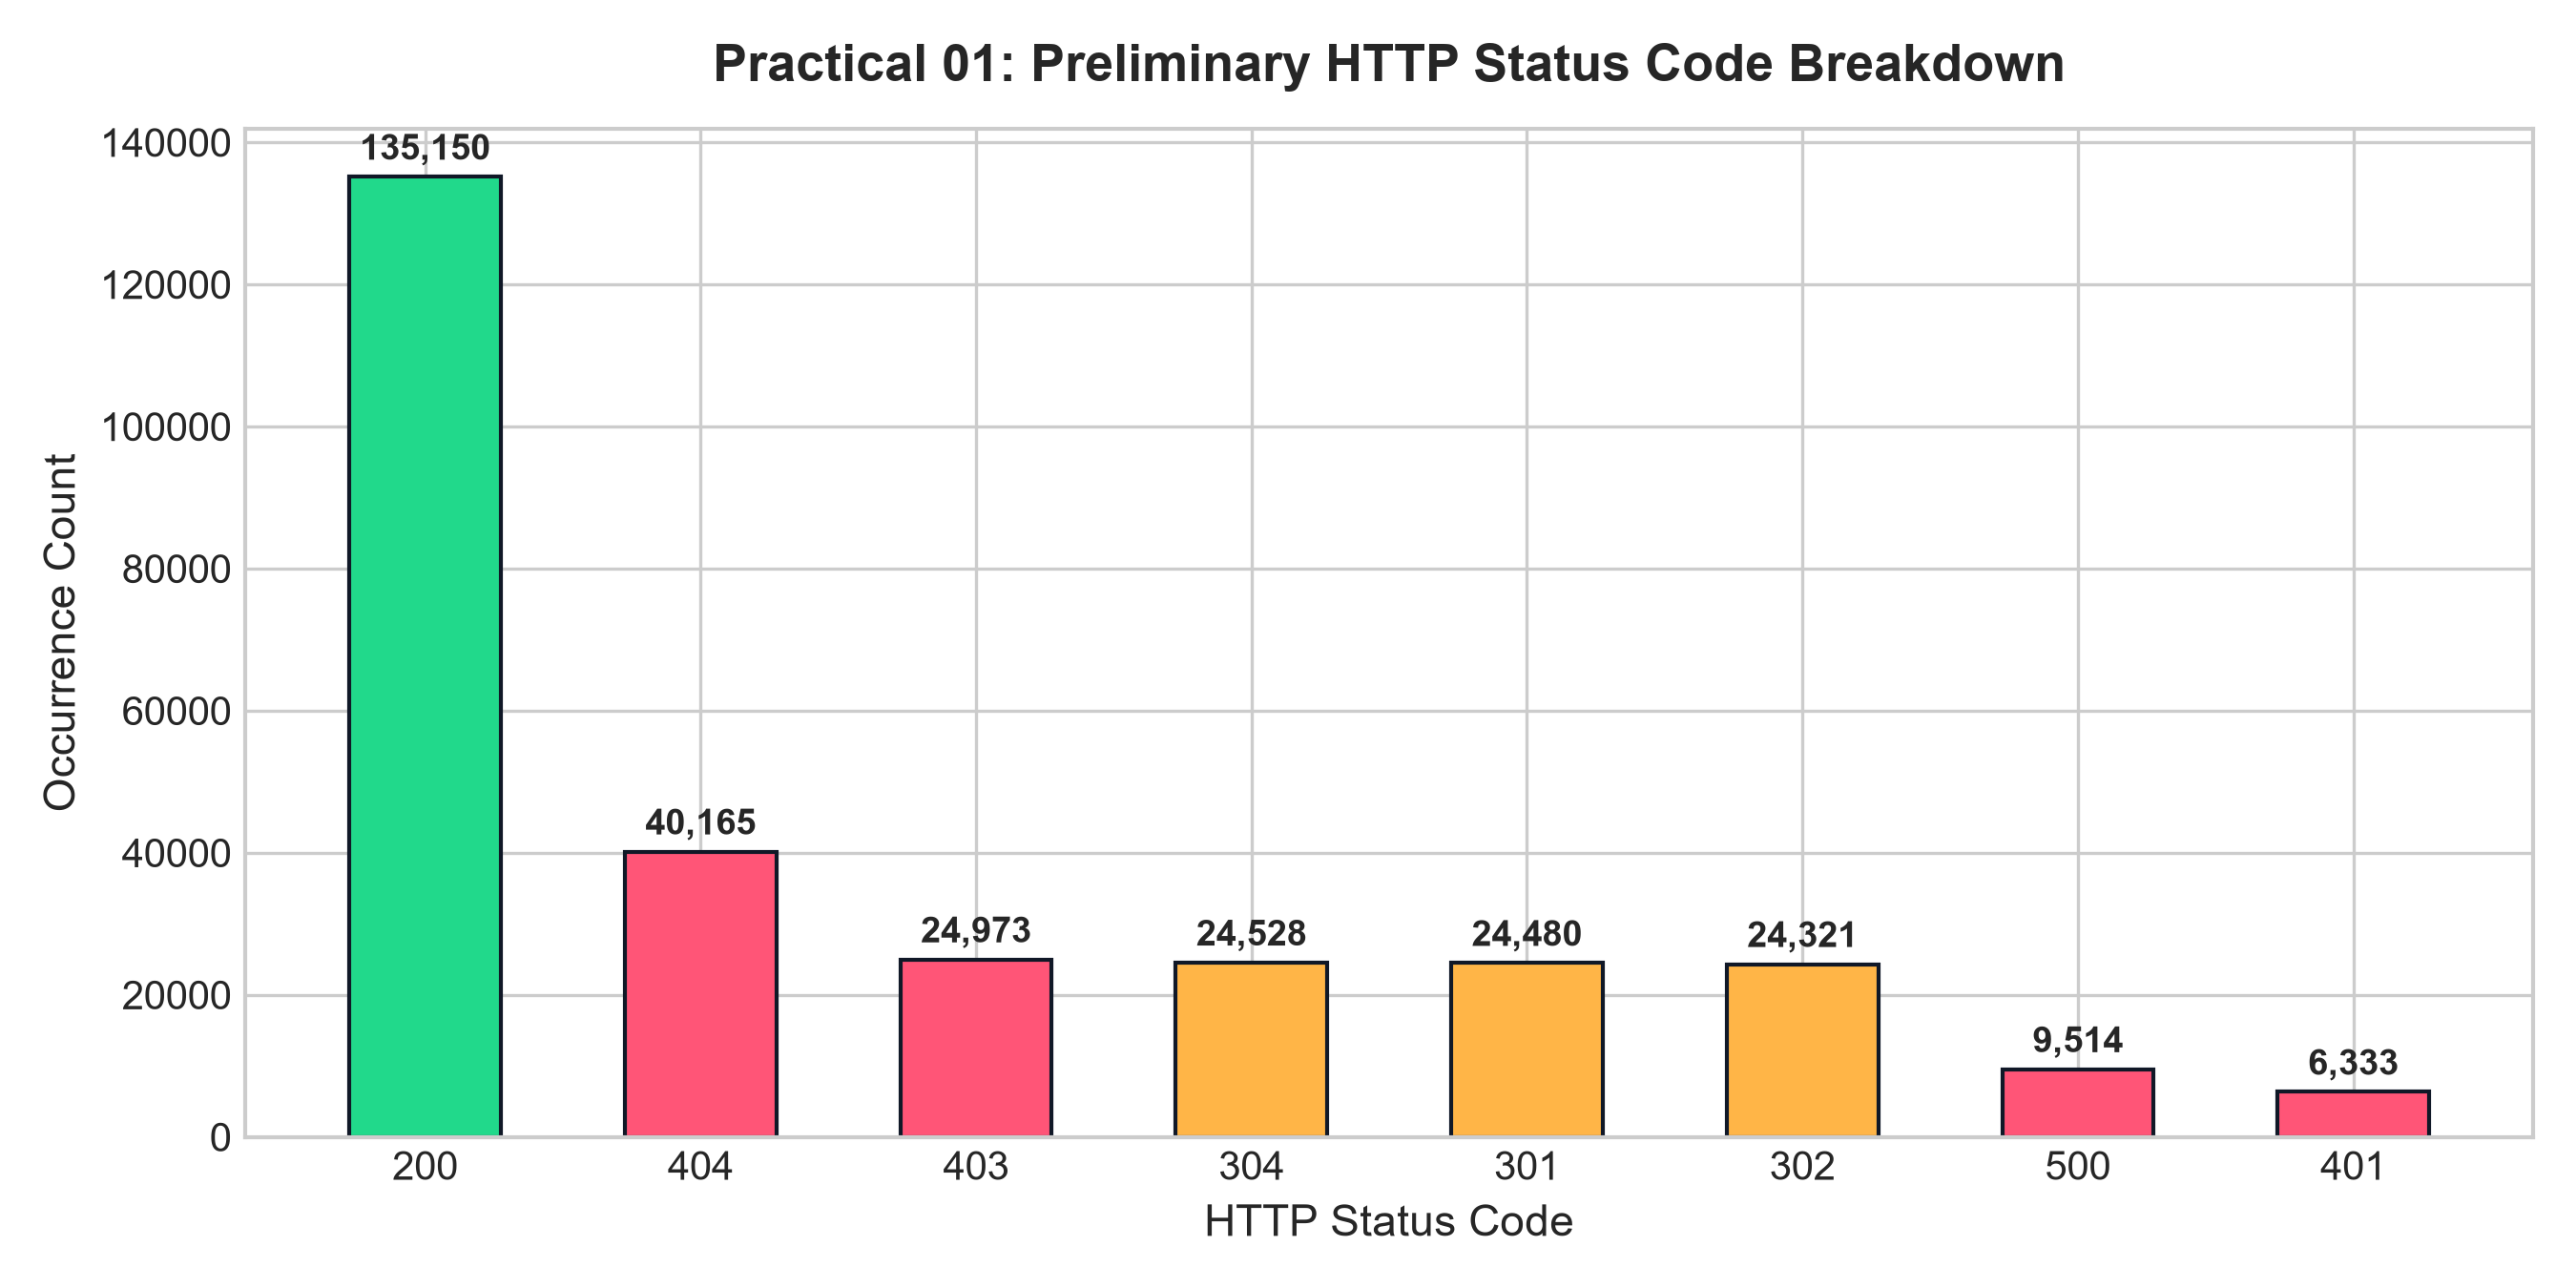

In [5]:
# 1. Line Length Distribution
plt.figure(figsize=(10, 4.5), dpi=150)
plt.hist(line_lengths, bins=80, color="#1687FF", edgecolor="#060912", alpha=0.85)
plt.title("Line Character Length Distribution (Bytes)", fontsize=12, fontweight="bold")
plt.xlabel("Line Length (Characters)", fontsize=10)
plt.ylabel("Line Count", fontsize=10)
plt.axvline(np.mean(line_lengths), color="#FF5577", linestyle="--", label=f"Mean ({np.mean(line_lengths):.1f})")
plt.axvline(np.median(line_lengths), color="#21D98B", linestyle=":", label=f"Median ({np.median(line_lengths):.1f})")
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'line_length_distribution.png')
plt.show()

# 2. HTTP Methods Breakdown
plt.figure(figsize=(8, 4), dpi=150)
methods = [k for k, _ in methods_counter.most_common(5)]
counts = [v for _, v in methods_counter.most_common(5)]
plt.bar(methods, counts, color=["#22D3EE", "#1687FF", "#21D98B", "#FFB547"], width=0.55)
plt.title("Preliminary HTTP Method Distribution", fontsize=12, fontweight="bold")
plt.xlabel("HTTP Method", fontsize=10)
plt.ylabel("Request Count", fontsize=10)
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'top_methods_preliminary.png')
plt.show()

# 3. HTTP Status Codes Breakdown
plt.figure(figsize=(9, 4), dpi=150)
top_s = [k for k, _ in status_counter.most_common(6)]
s_cnt = [v for _, v in status_counter.most_common(6)]
colors = ["#21D98B" if s.startswith("2") else ("#FFB547" if s.startswith("3") else "#FF5577") for s in top_s]
plt.bar(top_s, s_cnt, color=colors, width=0.55)
plt.title("Preliminary HTTP Status Code Breakdown", fontsize=12, fontweight="bold")
plt.xlabel("Status Code", fontsize=10)
plt.ylabel("Request Count", fontsize=10)
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'top_status_preliminary.png')
plt.show()


---
## 8. IDENTIFICATION OF CRITICAL CYBERSECURITY FIELDS

| Identified Field | Token | Security Role in Downstream Practicals |
|---|---|---|
| **Resource URI & Payload** | `%r` | Primary vector for SQLi, XSS, Path Traversal, and SSRF detection. Evaluated for Shannon entropy and character ratios. |
| **Client IP Address** | `%h` | Grouping key for Session & Temporal metrics (requests per IP per 1 min, velocity per second, burst ratio). |
| **Timestamp** | `%t` | Time-delta calculation ($\Delta t = t_i - t_{i-1}$) for identifying high-velocity automated DDoS HTTP Floods. |
| **Status Code** | `%>s` | Anomaly diagnostics: `401 Unauthorized` (Brute Force), `404 Not Found` (Directory Fuzzing), `503/429` (DDoS Floods). |
| **User-Agent** | `%{User-Agent}i` | Signature analysis to flag automated vulnerability scanners (`sqlmap`, `nikto`, `masscan`, `gobuster`). |